In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import LinearSVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, make_scorer, confusion_matrix, mean_squared_error, mean_absolute_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier

from scipy.stats import randint, uniform

In [2]:
df=pd.read_csv('data/car_insurance_claim.csv')
pd.set_option('display.max_columns', None)
df.head(10)

,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,"$67,349",No,$0,z_No,M,PhD,Professional,14,Private,"$14,230",11,Minivan,yes,"$4,461",2,No,3,$0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,"$91,449",No,"$257,252",z_No,M,z_High School,z_Blue Collar,22,Commercial,"$14,940",1,Minivan,yes,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,"$52,881",No,$0,z_No,M,Bachelors,Manager,26,Private,"$21,970",1,Van,yes,$0,0,No,2,$0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,"$16,039",No,"$124,191",Yes,z_F,z_High School,Clerical,5,Private,"$4,010",4,z_SUV,no,"$38,690",2,No,3,$0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,NaN,No,"$306,251",Yes,M,<High School,z_Blue Collar,32,Private,"$15,440",7,Minivan,yes,$0,0,No,0,$0,6.0,0,Highly Urban/ Urban
5,743146596,0,17MAY49,50.0,0,NaN,"$114,986",No,"$243,925",Yes,z_F,PhD,Doctor,36,Private,"$18,000",1,z_SUV,no,"$19,217",2,Yes,3,$0,17.0,0,Highly Urban/ Urban
6,871024631,0,05MAY65,34.0,1,12.0,"$125,301",Yes,$0,z_No,z_F,Bachelors,z_Blue Collar,46,Commercial,"$17,430",1,Sports Car,no,$0,0,No,0,"$2,946",7.0,1,Highly Urban/ Urban
7,792300541,0,28FEB45,54.0,0,NaN,"$18,755",No,NaN,Yes,z_F,<High School,z_Blue Collar,33,Private,"$8,780",1,z_SUV,no,$0,0,No,0,$0,1.0,0,Highly Urban/ Urban
8,7945239,1,17SEP59,40.0,1,11.0,"$50,815",Yes,$0,z_No,M,z_High School,Manager,21,Private,"$18,930",6,Minivan,no,"$3,295",1,No,2,"$6,477",1.0,1,Highly Urban/ Urban
9,3577610,0,21AUG55,44.0,2,12.0,"$43,486",Yes,$0,z_No,z_F,z_High School,z_Blue Collar,30,Commercial,"$5,900",10,z_SUV,no,$0,0,No,0,$0,10.0,0,z_Highly Rural/ Rural


### make a copy of the dataframe


In [3]:
data_df= df.copy()


In [4]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10302 entries, 0 to 10301
Data columns (total 27 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ID          10302 non-null  int64  
 1   KIDSDRIV    10302 non-null  int64  
 2   BIRTH       10302 non-null  object 
 3   AGE         10295 non-null  float64
 4   HOMEKIDS    10302 non-null  int64  
 5   YOJ         9754 non-null   float64
 6   INCOME      9732 non-null   object 
 7   PARENT1     10302 non-null  object 
 8   HOME_VAL    9727 non-null   object 
 9   MSTATUS     10302 non-null  object 
 10  GENDER      10302 non-null  object 
 11  EDUCATION   10302 non-null  object 
 12  OCCUPATION  9637 non-null   object 
 13  TRAVTIME    10302 non-null  int64  
 14  CAR_USE     10302 non-null  object 
 15  BLUEBOOK    10302 non-null  object 
 16  TIF         10302 non-null  int64  
 17  CAR_TYPE    10302 non-null  object 
 18  RED_CAR     10302 non-null  object 
 19  OLDCLAIM    10302 non-nul

In [5]:
#check for duplicates
data_df.duplicated().sum()

np.int64(1)

In [6]:
data_df.drop_duplicates(inplace=True)
data_df.columns

Index(['ID', 'KIDSDRIV', 'BIRTH', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME',
       'PARENT1', 'HOME_VAL', 'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION',
       'TRAVTIME', 'CAR_USE', 'BLUEBOOK', 'TIF', 'CAR_TYPE', 'RED_CAR',
       'OLDCLAIM', 'CLM_FREQ', 'REVOKED', 'MVR_PTS', 'CLM_AMT', 'CAR_AGE',
       'CLAIM_FLAG', 'URBANICITY'],
      dtype='object')

In [7]:
#remove $ symbol from currency columns
currency_culs=['INCOME','HOME_VAL','BLUEBOOK','OLDCLAIM','CLM_AMT']

def remove_dollar(data,cols):
    for col in cols:
        data[col]=data[col].replace('[\\$,]','',regex=True).astype('Int64')
    return data
data_df= remove_dollar(data_df,currency_culs)
data_df.head(10)

,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,67349,No,0,z_No,M,PhD,Professional,14,Private,14230,11,Minivan,yes,4461,2,No,3,0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,91449,No,257252,z_No,M,z_High School,z_Blue Collar,22,Commercial,14940,1,Minivan,yes,0,0,No,0,0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,52881,No,0,z_No,M,Bachelors,Manager,26,Private,21970,1,Van,yes,0,0,No,2,0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,16039,No,124191,Yes,z_F,z_High School,Clerical,5,Private,4010,4,z_SUV,no,38690,2,No,3,0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,<NA>,No,306251,Yes,M,<High School,z_Blue Collar,32,Private,15440,7,Minivan,yes,0,0,No,0,0,6.0,0,Highly Urban/ Urban
5,743146596,0,17MAY49,50.0,0,NaN,114986,No,243925,Yes,z_F,PhD,Doctor,36,Private,18000,1,z_SUV,no,19217,2,Yes,3,0,17.0,0,Highly Urban/ Urban
6,871024631,0,05MAY65,34.0,1,12.0,125301,Yes,0,z_No,z_F,Bachelors,z_Blue Collar,46,Commercial,17430,1,Sports Car,no,0,0,No,0,2946,7.0,1,Highly Urban/ Urban
7,792300541,0,28FEB45,54.0,0,NaN,18755,No,<NA>,Yes,z_F,<High School,z_Blue Collar,33,Private,8780,1,z_SUV,no,0,0,No,0,0,1.0,0,Highly Urban/ Urban
8,7945239,1,17SEP59,40.0,1,11.0,50815,Yes,0,z_No,M,z_High School,Manager,21,Private,18930,6,Minivan,no,3295,1,No,2,6477,1.0,1,Highly Urban/ Urban
9,3577610,0,21AUG55,44.0,2,12.0,43486,Yes,0,z_No,z_F,z_High School,z_Blue Collar,30,Commercial,5900,10,z_SUV,no,0,0,No,0,0,10.0,0,z_Highly Rural/ Rural


In [8]:
#remove the z_prefix
prefix_cols= ['EDUCATION','OCCUPATION','CAR_TYPE','GENDER','MSTATUS','URBANICITY']
def remove_z_prefix(data,cols):
    for col in cols:
        data[col]=data[col].replace('[z_]','',regex=True)
    return data
data_df= remove_z_prefix(data_df,prefix_cols)
data_df.head(10)


,ID,KIDSDRIV,BIRTH,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY
0,63581743,0,16MAR39,60.0,0,11.0,67349,No,0,No,M,PhD,Professional,14,Private,14230,11,Minivan,yes,4461,2,No,3,0,18.0,0,Highly Urban/ Urban
1,132761049,0,21JAN56,43.0,0,11.0,91449,No,257252,No,M,High School,Blue Collar,22,Commercial,14940,1,Minivan,yes,0,0,No,0,0,1.0,0,Highly Urban/ Urban
2,921317019,0,18NOV51,48.0,0,11.0,52881,No,0,No,M,Bachelors,Manager,26,Private,21970,1,Van,yes,0,0,No,2,0,10.0,0,Highly Urban/ Urban
3,727598473,0,05MAR64,35.0,1,10.0,16039,No,124191,Yes,F,High School,Clerical,5,Private,4010,4,SUV,no,38690,2,No,3,0,10.0,0,Highly Urban/ Urban
4,450221861,0,05JUN48,51.0,0,14.0,<NA>,No,306251,Yes,M,<High School,Blue Collar,32,Private,15440,7,Minivan,yes,0,0,No,0,0,6.0,0,Highly Urban/ Urban
5,743146596,0,17MAY49,50.0,0,NaN,114986,No,243925,Yes,F,PhD,Doctor,36,Private,18000,1,SUV,no,19217,2,Yes,3,0,17.0,0,Highly Urban/ Urban
6,871024631,0,05MAY65,34.0,1,12.0,125301,Yes,0,No,F,Bachelors,Blue Collar,46,Commercial,17430,1,Sports Car,no,0,0,No,0,2946,7.0,1,Highly Urban/ Urban
7,792300541,0,28FEB45,54.0,0,NaN,18755,No,<NA>,Yes,F,<High School,Blue Collar,33,Private,8780,1,SUV,no,0,0,No,0,0,1.0,0,Highly Urban/ Urban
8,7945239,1,17SEP59,40.0,1,11.0,50815,Yes,0,No,M,High School,Manager,21,Private,18930,6,Minivan,no,3295,1,No,2,6477,1.0,1,Highly Urban/ Urban
9,3577610,0,21AUG55,44.0,2,12.0,43486,Yes,0,No,F,High School,Blue Collar,30,Commercial,5900,10,SUV,no,0,0,No,0,0,10.0,0,Highly Rural/ Rural


In [9]:
#drop useless cols
data_df.drop(['ID','BIRTH'],axis=1,inplace=True)


In [10]:
#check for non-zero values for CLM_ATM where CLAIM_FLAG =1
mask= (data_df['CLM_AMT']>0) & (data_df['CLAIM_FLAG']==0)
data_df[mask]

,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CLM_AMT,CAR_AGE,CLAIM_FLAG,URBANICITY


<Axes: xlabel='CLM_AMT', ylabel='Count'>

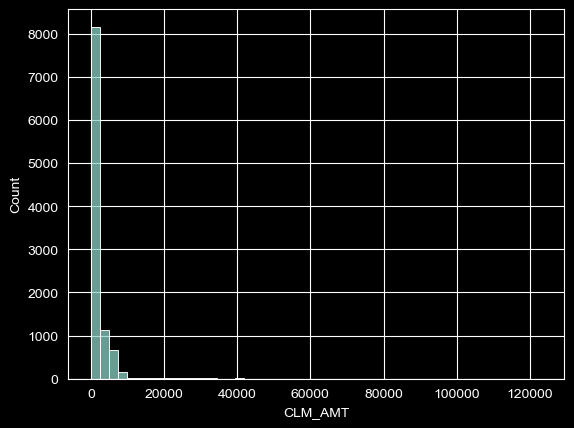

In [11]:
#check the distribution of new claim values using histogram
sns.histplot(data_df['CLM_AMT'],bins=50)

In [12]:
bins = [0.0, 5000, 10_000, 15_000, 20_000, 25_000, 30_000, 35_000, 40_000, 45_000, 50_000,np.inf]
labels = np.arange(1, 12)
data_df['claim_val'] = pd.cut(data_df['CLM_AMT'], bins=bins, labels=labels, include_lowest=True)

In [13]:
y= data_df.CLAIM_FLAG
X= data_df.drop(['CLAIM_FLAG','CLM_AMT'],axis=1)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=7,stratify=X['claim_val'])

In [14]:
#check positive to negative class ratio in train and test labels
test_ratio=round((y_test.sum()/len(y_test))*100)
train_ratio=round((y_train.sum()/len(y_train))*100)
print(f'train ratio :{train_ratio}%')
print(f'test ratio :{test_ratio}%')


train ratio :26%
test ratio :27%


In [15]:
#remove bins
for set_ in (X_train,X_test):
    set_.drop(columns=['claim_val'],inplace=True)

### Exploratory Data Analysis



In [16]:
eda_test_data=X_train.copy()
eda_test_data['CLAIM_FLAG']=y_train


In [17]:
eda_test_data.columns

Index(['KIDSDRIV', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'PARENT1', 'HOME_VAL',
       'MSTATUS', 'GENDER', 'EDUCATION', 'OCCUPATION', 'TRAVTIME', 'CAR_USE',
       'BLUEBOOK', 'TIF', 'CAR_TYPE', 'RED_CAR', 'OLDCLAIM', 'CLM_FREQ',
       'REVOKED', 'MVR_PTS', 'CAR_AGE', 'URBANICITY', 'CLAIM_FLAG'],
      dtype='object')

In [18]:
#fixing binary cols
binary_cols= ['PARENT1','MSTATUS','GENDER','RED_CAR','REVOKED']

#define map values
mapping={
     'yes':1,
     'no':0,
     'M':1,
     'F':2,
     'YES':1,
     'NO':0,
     'Yes':1,
     'No':0,
 }
def map_values(data,cols,map):
    for col in cols:
        data[col]=data[col].map(map)
    return data
eda_test_data=map_values(eda_test_data,binary_cols,mapping)
eda_test_data.head(10)

,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,GENDER,EDUCATION,OCCUPATION,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CAR_AGE,URBANICITY,CLAIM_FLAG
808,0,35.0,2,13.0,35907,1,160171,0,2,High School,Clerical,53,Private,8590,4,SUV,0,1278,2,0,6,NaN,Highly Rural/ Rural,0
7459,0,53.0,0,14.0,62731,0,214682,1,2,Masters,Lawyer,20,Private,13070,1,Sports Car,0,0,0,0,0,NaN,Highly Urban/ Urban,0
836,0,43.0,2,13.0,126496,0,<NA>,1,1,Masters,NaN,22,Commercial,26980,7,Panel Truck,1,0,0,0,5,16.0,Highly Urban/ Urban,0
2110,0,37.0,0,11.0,23338,0,152954,1,2,<High School,Blue Collar,24,Private,7530,7,Sports Car,0,6566,2,0,0,5.0,Highly Urban/ Urban,1
9339,0,54.0,0,15.0,<NA>,0,169273,1,2,<High School,Blue Collar,22,Private,10490,1,SUV,0,0,0,0,0,1.0,Highly Urban/ Urban,0
9757,0,42.0,0,15.0,73551,0,0,0,2,Masters,Lawyer,33,Private,13060,1,Minivan,0,23213,2,1,4,8.0,Highly Urban/ Urban,1
7383,0,37.0,2,12.0,158489,0,415676,1,2,PhD,Lawyer,58,Private,5200,1,SUV,0,0,0,0,1,16.0,Highly Urban/ Urban,1
2122,0,43.0,0,10.0,125575,0,308112,1,2,Bachelors,Manager,21,Private,17430,3,Minivan,0,0,0,0,1,13.0,Highly Urban/ Urban,0
6605,0,42.0,2,12.0,73661,1,0,0,2,<High School,Blue Collar,45,Commercial,25940,4,Minivan,0,0,0,0,0,1.0,Highly Rural/ Rural,0
785,0,48.0,0,15.0,81940,0,263363,1,2,High School,Manager,5,Private,17270,1,Sports Car,0,17691,1,1,6,1.0,Highly Urban/ Urban,0


## Correlation Matrix

<Axes: >

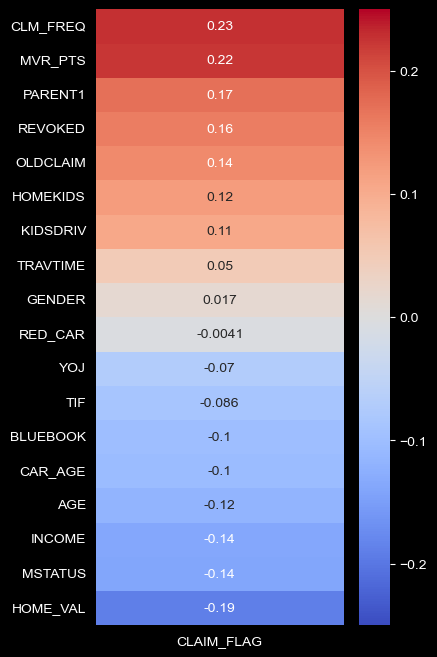

In [19]:
corr_matrix = eda_test_data.corr(numeric_only=True).sort_values(by='CLAIM_FLAG', ascending=False)
corr_matrix_no_claim = corr_matrix.drop('CLAIM_FLAG')
fig, ax = plt.subplots(figsize=(4, 8))
sns.heatmap(corr_matrix_no_claim[['CLAIM_FLAG']], cmap='coolwarm', annot=True, vmax=0.25, vmin=-0.25)

In [20]:
X_train_raw= X_train.copy()

cols_to_drop= ['RED_CAR']

X_train_raw.drop(cols_to_drop, axis=1, inplace=True)

In [21]:
#missing value removal/replacement
X_train_raw.isnull().sum()


KIDSDRIV        0
AGE             7
HOMEKIDS        0
YOJ           425
INCOME        452
PARENT1         0
HOME_VAL      476
MSTATUS         0
GENDER          0
EDUCATION       0
OCCUPATION    545
TRAVTIME        0
CAR_USE         0
BLUEBOOK        0
TIF             0
CAR_TYPE        0
OLDCLAIM        0
CLM_FREQ        0
REVOKED         0
MVR_PTS         0
CAR_AGE       518
URBANICITY      0
dtype: int64

In [22]:
#create imputer to fill out missing numerical values
knn_imputer= KNNImputer(n_neighbors=2)

#define num cols
num_cols_df=X_train_raw.select_dtypes(include=['number'])
num_cols=num_cols_df.columns.tolist()

#define categorical cols
cat_cols_df= X_train_raw.select_dtypes(include=['object'])
cat_cols= cat_cols_df.columns.tolist()

In [23]:
#impute the values using knn
def num_knn_impute(data,cols,imputer):
    data=data[cols]
    data_imp=pd.DataFrame(imputer.fit_transform(data),columns=data.columns)
    return data_imp

num_test_data_imp=num_knn_impute(X_train_raw,num_cols,knn_imputer)

In [24]:
#create imputer to fill out missing categorical values
simple_imputer= SimpleImputer(strategy='most_frequent')

def cat_simp_imputer(data,cols,imputer):
    data=data[cols]
    data_imp=pd.DataFrame(imputer.fit_transform(data),columns=data.columns)
    return data_imp

cat_test_data_imputed= cat_simp_imputer(X_train_raw,cat_cols,simple_imputer)


In [25]:
#join two df with concat function
train_imputed_df=pd.concat([num_test_data_imp,cat_test_data_imputed],axis=1)
train_imputed_df.head(10)

,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,HOME_VAL,TRAVTIME,BLUEBOOK,TIF,OLDCLAIM,CLM_FREQ,MVR_PTS,CAR_AGE,PARENT1,MSTATUS,GENDER,EDUCATION,OCCUPATION,CAR_USE,CAR_TYPE,REVOKED,URBANICITY
0,0.0,35.0,2.0,13.0,35907.0,160171.0,53.0,8590.0,4.0,1278.0,2.0,6.0,6.5,Yes,No,F,High School,Clerical,Private,SUV,No,Highly Rural/ Rural
1,0.0,53.0,0.0,14.0,62731.0,214682.0,20.0,13070.0,1.0,0.0,0.0,0.0,6.5,No,Yes,F,Masters,Lawyer,Private,Sports Car,No,Highly Urban/ Urban
2,0.0,43.0,2.0,13.0,126496.0,77578.0,22.0,26980.0,7.0,0.0,0.0,5.0,16.0,No,Yes,M,Masters,Blue Collar,Commercial,Panel Truck,No,Highly Urban/ Urban
3,0.0,37.0,0.0,11.0,23338.0,152954.0,24.0,7530.0,7.0,6566.0,2.0,0.0,5.0,No,Yes,F,<High School,Blue Collar,Private,Sports Car,No,Highly Urban/ Urban
4,0.0,54.0,0.0,15.0,62941.0,169273.0,22.0,10490.0,1.0,0.0,0.0,0.0,1.0,No,Yes,F,<High School,Blue Collar,Private,SUV,No,Highly Urban/ Urban
5,0.0,42.0,0.0,15.0,73551.0,0.0,33.0,13060.0,1.0,23213.0,2.0,4.0,8.0,No,No,F,Masters,Lawyer,Private,Minivan,Yes,Highly Urban/ Urban
6,0.0,37.0,2.0,12.0,158489.0,415676.0,58.0,5200.0,1.0,0.0,0.0,1.0,16.0,No,Yes,F,PhD,Lawyer,Private,SUV,No,Highly Urban/ Urban
7,0.0,43.0,0.0,10.0,125575.0,308112.0,21.0,17430.0,3.0,0.0,0.0,1.0,13.0,No,Yes,F,Bachelors,Manager,Private,Minivan,No,Highly Urban/ Urban
8,0.0,42.0,2.0,12.0,73661.0,0.0,45.0,25940.0,4.0,0.0,0.0,0.0,1.0,Yes,No,F,<High School,Blue Collar,Commercial,Minivan,No,Highly Rural/ Rural
9,0.0,48.0,0.0,15.0,81940.0,263363.0,5.0,17270.0,1.0,17691.0,1.0,6.0,1.0,No,Yes,F,High School,Manager,Private,Sports Car,Yes,Highly Urban/ Urban


In [26]:
train_imputed_df.isnull().sum()

KIDSDRIV      0
AGE           0
HOMEKIDS      0
YOJ           0
INCOME        0
HOME_VAL      0
TRAVTIME      0
BLUEBOOK      0
TIF           0
OLDCLAIM      0
CLM_FREQ      0
MVR_PTS       0
CAR_AGE       0
PARENT1       0
MSTATUS       0
GENDER        0
EDUCATION     0
OCCUPATION    0
CAR_USE       0
CAR_TYPE      0
REVOKED       0
URBANICITY    0
dtype: int64

## Categorical Feature Encoding

In [27]:
cat_test_data_imputed.nunique()

PARENT1       2
MSTATUS       2
GENDER        2
EDUCATION     5
OCCUPATION    8
CAR_USE       2
CAR_TYPE      6
REVOKED       2
URBANICITY    2
dtype: int64

In [28]:
#ordinal features (have hierarchy)
cat_cols_ord=['EDUCATION']
#binary features (one or another)
cat_cols_bin=['PARENT1','MSTATUS','GENDER','CAR_USE','REVOKED','URBANICITY']
#one-hot features
cat_cols_hot=['OCCUPATION','CAR_TYPE']

In [29]:
#create the encoders
education_rank = [['<High School', 'High School', 'Bachelors', 'Masters', 'PhD']]

ord_encoder = OrdinalEncoder(categories=education_rank)

bin_encoder = OrdinalEncoder()

one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [30]:
ord_encoded = ord_encoder.fit_transform(cat_test_data_imputed[cat_cols_ord])

# Encode binaries
bin_encoded = bin_encoder.fit_transform(cat_test_data_imputed[cat_cols_bin])

# One-hot encoding
one_hot_encoded = one_hot_encoder.fit_transform(cat_test_data_imputed[cat_cols_hot])

In [31]:
# Create dfs for each array
ord_encoded_df = pd.DataFrame(ord_encoded)
ord_encoded_df.columns = cat_cols_ord

bin_encoded_df = pd.DataFrame(bin_encoded)
bin_encoded_df.columns = cat_cols_bin

one_hot_encoded_df = pd.DataFrame(one_hot_encoded)
one_hot_encoded_df.columns = one_hot_encoder.get_feature_names_out()

# Join encoded dfs to a single df and show head
all_cat_encoded_df = pd.concat([ord_encoded_df, bin_encoded_df, one_hot_encoded_df], axis=1)
all_cat_encoded_df.head(10)

,EDUCATION,PARENT1,MSTATUS,GENDER,CAR_USE,REVOKED,URBANICITY,OCCUPATION_Blue Collar,OCCUPATION_Clerical,OCCUPATION_Doctor,OCCUPATION_Home Maker,OCCUPATION_Lawyer,OCCUPATION_Manager,OCCUPATION_Professional,OCCUPATION_Student,CAR_TYPE_Minivan,CAR_TYPE_Panel Truck,CAR_TYPE_Pickup,CAR_TYPE_SUV,CAR_TYPE_Sports Car,CAR_TYPE_Van
0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,3.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,3.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6,4.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,2.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
8,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [32]:
# Join numerical and categorical data
X_train_cleaned = pd.concat([train_imputed_df[num_cols], all_cat_encoded_df], axis=1)
X_train_cleaned.head(10)

,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,HOME_VAL,TRAVTIME,BLUEBOOK,TIF,OLDCLAIM,CLM_FREQ,MVR_PTS,CAR_AGE,EDUCATION,PARENT1,MSTATUS,GENDER,CAR_USE,REVOKED,URBANICITY,OCCUPATION_Blue Collar,OCCUPATION_Clerical,OCCUPATION_Doctor,OCCUPATION_Home Maker,OCCUPATION_Lawyer,OCCUPATION_Manager,OCCUPATION_Professional,OCCUPATION_Student,CAR_TYPE_Minivan,CAR_TYPE_Panel Truck,CAR_TYPE_Pickup,CAR_TYPE_SUV,CAR_TYPE_Sports Car,CAR_TYPE_Van
0,0.0,35.0,2.0,13.0,35907.0,160171.0,53.0,8590.0,4.0,1278.0,2.0,6.0,6.5,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,53.0,0.0,14.0,62731.0,214682.0,20.0,13070.0,1.0,0.0,0.0,0.0,6.5,3.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,43.0,2.0,13.0,126496.0,77578.0,22.0,26980.0,7.0,0.0,0.0,5.0,16.0,3.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,37.0,0.0,11.0,23338.0,152954.0,24.0,7530.0,7.0,6566.0,2.0,0.0,5.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,54.0,0.0,15.0,62941.0,169273.0,22.0,10490.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5,0.0,42.0,0.0,15.0,73551.0,0.0,33.0,13060.0,1.0,23213.0,2.0,4.0,8.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6,0.0,37.0,2.0,12.0,158489.0,415676.0,58.0,5200.0,1.0,0.0,0.0,1.0,16.0,4.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,0.0,43.0,0.0,10.0,125575.0,308112.0,21.0,17430.0,3.0,0.0,0.0,1.0,13.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
8,0.0,42.0,2.0,12.0,73661.0,0.0,45.0,25940.0,4.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,0.0,48.0,0.0,15.0,81940.0,263363.0,5.0,17270.0,1.0,17691.0,1.0,6.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [33]:
# to avoid dummy variable trap,drop one column of each one hot encoded col
X_train_cleaned.drop(['OCCUPATION_Blue Collar' ,'CAR_TYPE_Minivan'], axis=1, inplace=True)

### Model Selection

In [34]:
# Define the classifiers to test
clfs = [
    ('Logistic Regression', LogisticRegression(solver='liblinear', max_iter=2000)),
    ('KNN', KNeighborsClassifier()),
    ('Decision Tree', DecisionTreeClassifier()),
    ('Random Forest', RandomForestClassifier(random_state=42)),
    ('Linear SVM', LinearSVC(random_state=42, max_iter=1000, dual='auto')),
    ('XGBoost', XGBClassifier(random_state=42)),
    ('AdaBoost', AdaBoostClassifier(random_state=42, algorithm='SAMME')),
    ('Gradient Boost', GradientBoostingClassifier(random_state=42)),
    ('Bagging', BaggingClassifier(random_state=42)),
    ('CatBoost', CatBoostClassifier(random_state=42, verbose=0)),
]

In [35]:
#creating kfold object
kf=KFold(n_splits=5,shuffle=True,random_state=42)

#dictionary to store results
results={}

for clf_name,clf in clfs:
    cv_score=cross_val_score(clf,X_train_cleaned,y_train,cv=kf,n_jobs=-1)
    results[clf_name]=cv_score

cv_score_df=pd.DataFrame(results)

Text(0.5, 1.0, 'cross_val_scores')

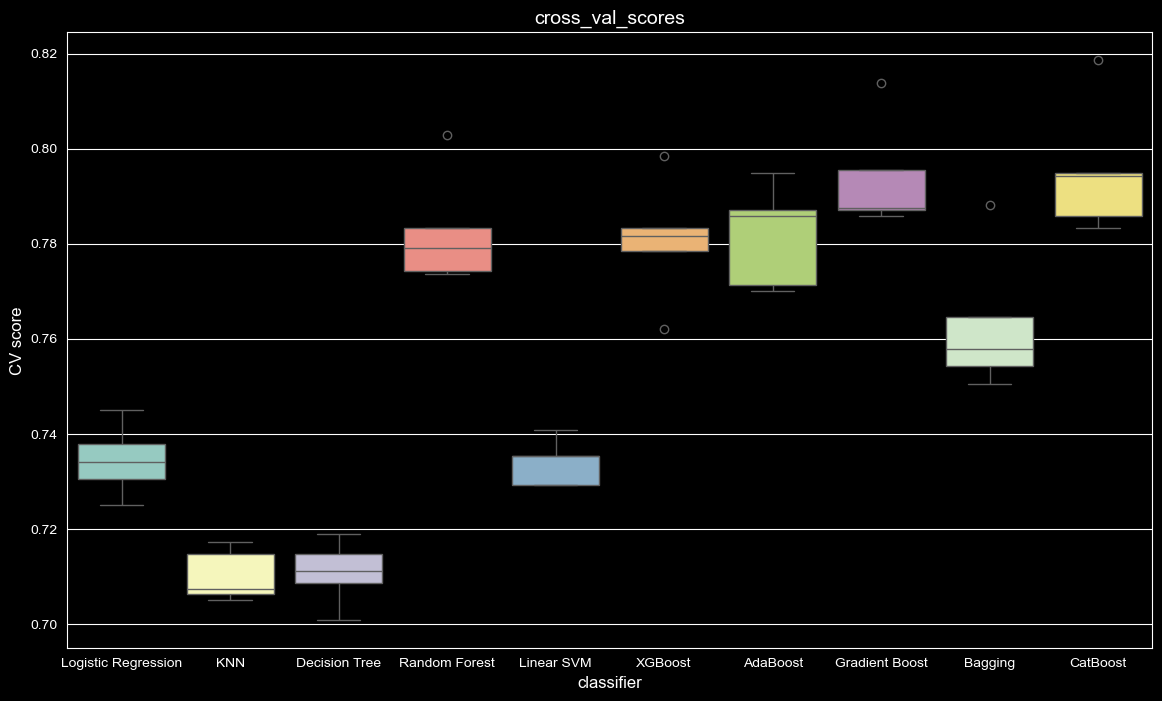

In [36]:
#plot the scores
fig,ax=plt.subplots(figsize=(14,8))
sns.boxplot(cv_score_df)

#add axis and labels
ax.set_xlabel('classifier',fontsize=12)
ax.set_ylabel('CV score',fontsize=12)
ax.set_title('cross_val_scores',fontsize=14)


### Feature Engineering

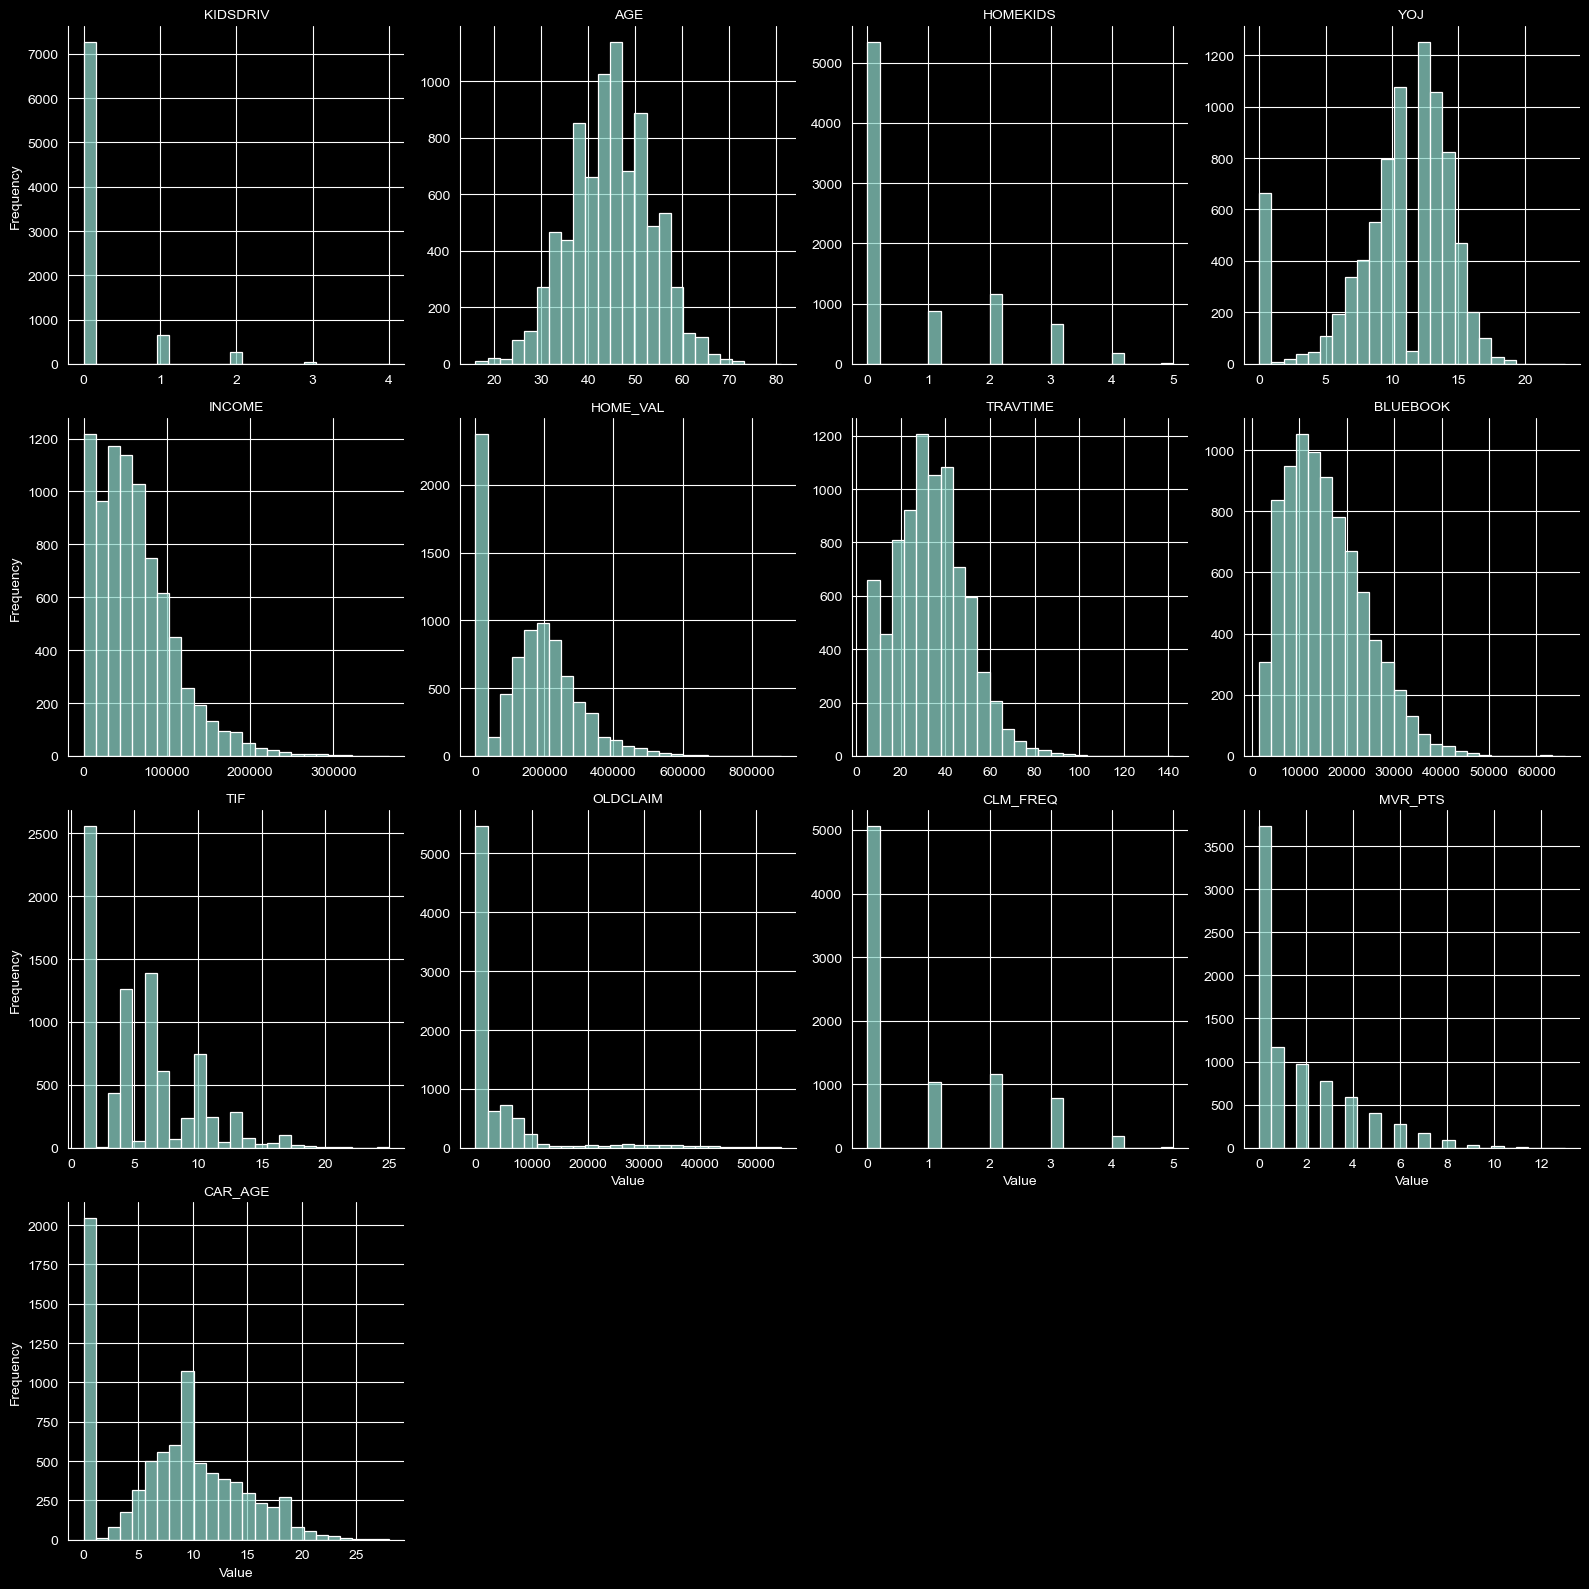

In [37]:
# Melt the DataFrame to long format
melted_X_train = X_train_cleaned[num_cols].melt(var_name='Column', value_name='Value')

# Create a FacetGrid
g = sns.FacetGrid(melted_X_train, col='Column', col_wrap=4, sharex=False, sharey=False, height=4)

# Map the sns.histplot to each facet
g.map(sns.histplot, 'Value', bins=25)

# Add titles and labels
g.set_axis_labels('Value', 'Frequency')
g.set_titles(col_template='{col_name}')

plt.tight_layout()
plt.show()

In [38]:
#list of skewed features
skewed_features=['INCOME','HOME_VAL','TRAVTIME','BLUEBOOK','TIF','MVR_PTS']

#function to take the sqrt of values
def sqrt_features(data_df,features):
    data=data_df.copy()
    for feature in features:
        data[feature]=np.sqrt(data[feature])
    return data
#call function
X_train_cleaned_sqrt=sqrt_features(X_train_cleaned,skewed_features)


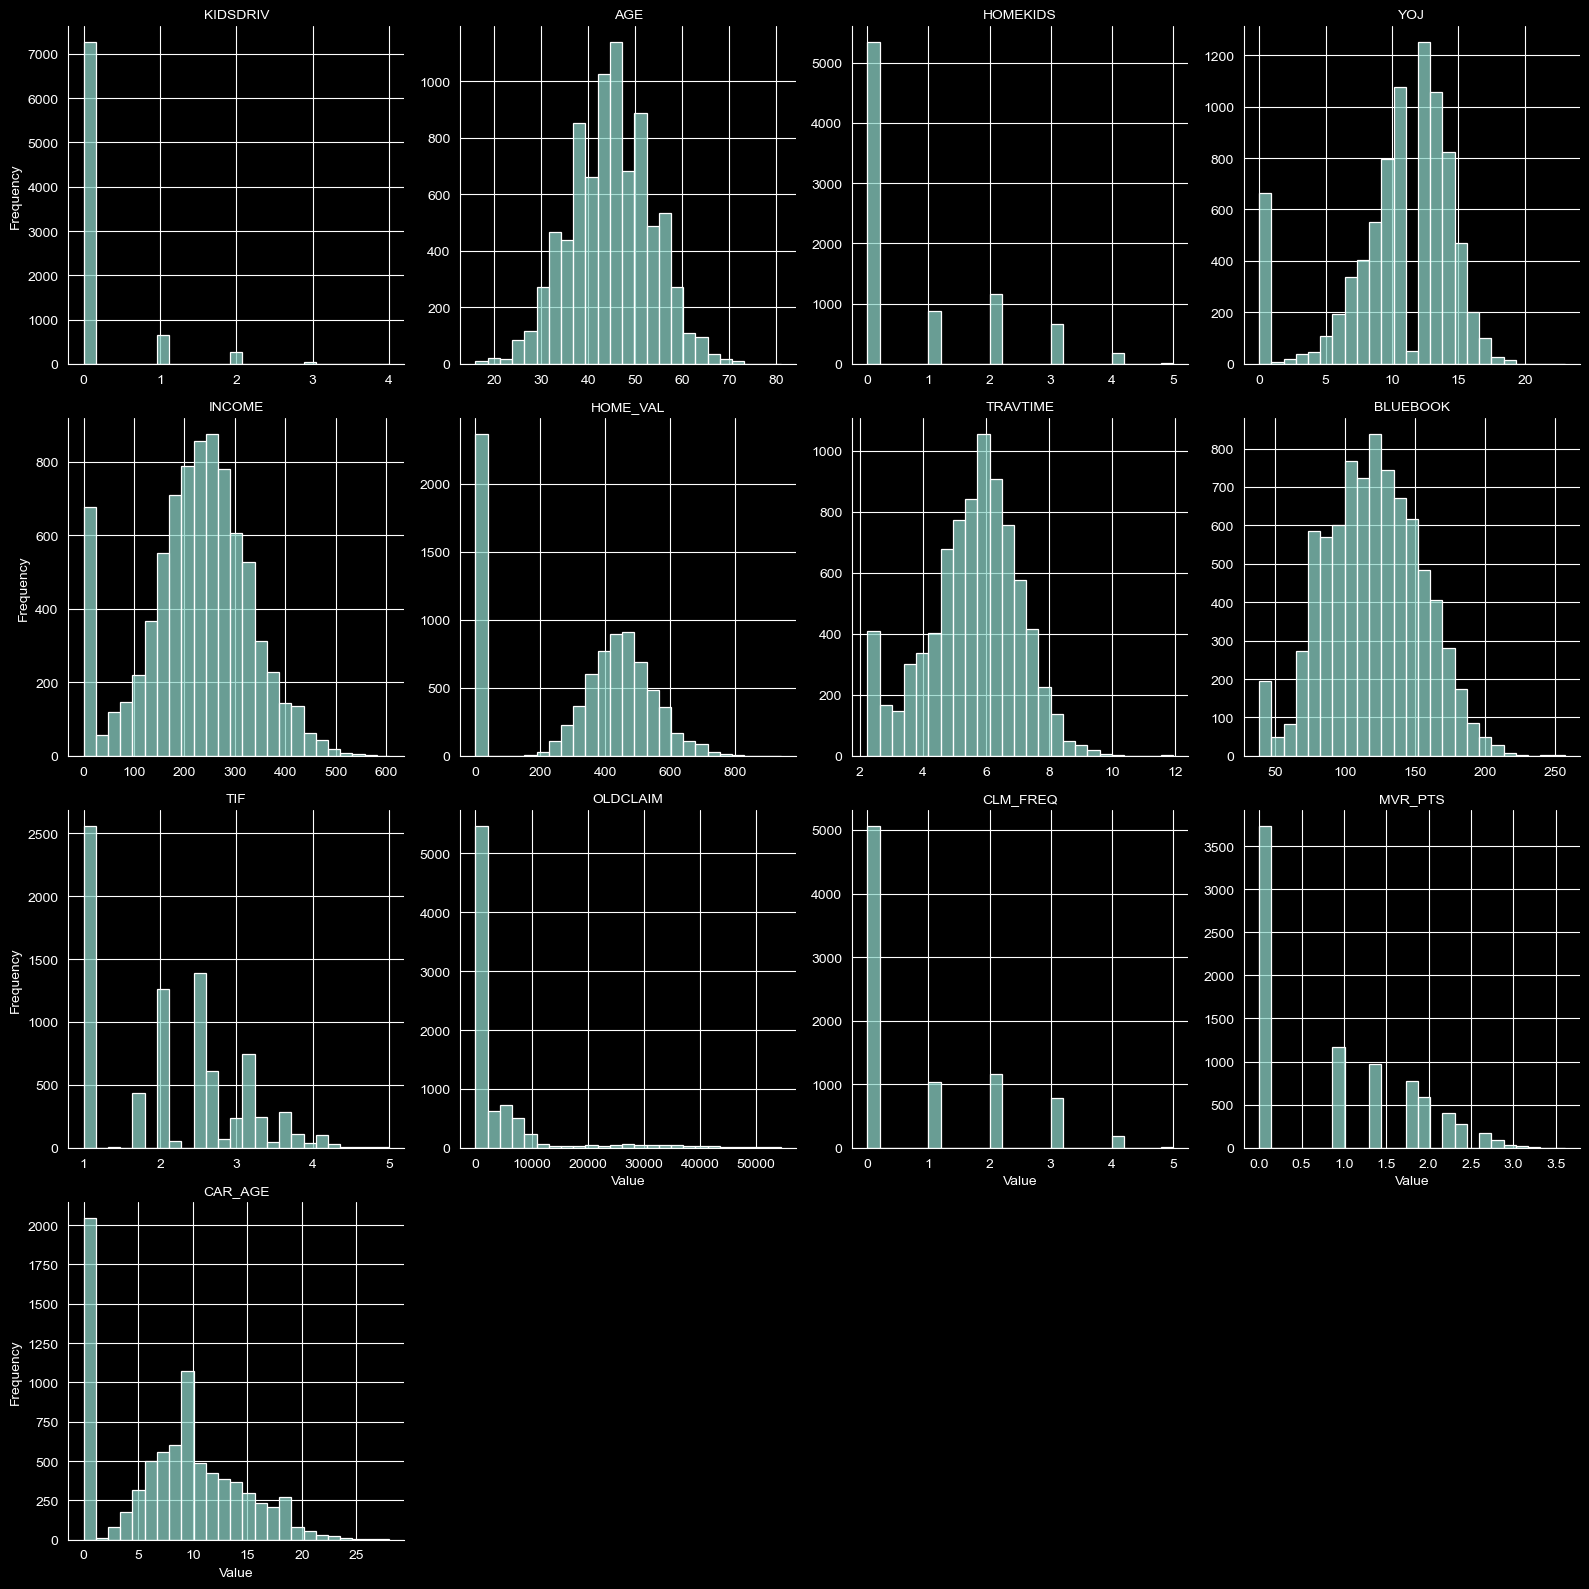

In [39]:

melted_X_train = X_train_cleaned_sqrt[num_cols].melt(var_name='Column', value_name='Value')


g = sns.FacetGrid(melted_X_train, col='Column', col_wrap=4, sharex=False, sharey=False, height=4)


g.map(sns.histplot, 'Value', bins=25)


g.set_axis_labels('Value', 'Frequency')
g.set_titles(col_template='{col_name}')

plt.tight_layout()
plt.show()

In [40]:
#check for any improvements using xgboost
xgb_clf=XGBClassifier(random_state=42)

cv_scores_sqrt = cross_val_score(xgb_clf,X_train_cleaned_sqrt,y_train,cv=kf,n_jobs=-1)
cv_scores = cross_val_score(xgb_clf,X_train_cleaned_sqrt,y_train,cv=kf,n_jobs=-1)

print(f'score without sqrts: {cv_scores.mean()}')
print(f'scores after sqrts: {cv_scores_sqrt.mean()}')


score without sqrts: 0.7808252427184466
scores after sqrts: 0.7808252427184466


### Feature scalling

In [41]:
#define function to scale features
def feature_scaler(data_df,features):
    data=data_df.copy()
    scaler = StandardScaler()
    scaler.fit(data[features])
    data[features]=scaler.transform(data[features])
    return data

X_train_cleaned_scaled=feature_scaler(X_train_cleaned_sqrt,num_cols)

In [42]:
#check for any improvements using scaling
xgb_clf=XGBClassifier(random_state=42)

cv_scores_scaled = cross_val_score(xgb_clf,X_train_cleaned_scaled,y_train,cv=kf,n_jobs=-1)
cv_scores = cross_val_score(xgb_clf,X_train_cleaned_sqrt,y_train,cv=kf,n_jobs=-1)

print(f'score without scaling: {cv_scores.mean()}')
print(f'scores after scaling {cv_scores_scaled.mean()}')


score without scaling: 0.7808252427184466
scores after scaling 0.7808252427184466


### Model Pipeline

In [43]:
X_train_cleaned= X_train_cleaned_scaled.copy()


In [44]:
#create custom transformer to drop red car column
class ColumnDropper(BaseEstimator, TransformerMixin):
    def __init__(self,cols_to_drop):
        self.cols_to_drop=cols_to_drop
    def fit(self,X,y=None):
        return self
    def transform(self,X):
        return X.drop(columns=self.cols_to_drop)
    def get_feature_names_out(self,input_features=None):
        return None

In [45]:
#Transformer to take sqrt of features
class SqrtTransformer(BaseEstimator, TransformerMixin):
    def __init__(self,cols_to_sqrt):
        self.cols_to_sqrt=cols_to_sqrt
    def fit(self,X,y=None):
        return self
    def transform(self,X):
        X[self.cols_to_sqrt]=np.sqrt(X[self.cols_to_sqrt])
        return X
    def get_feature_names_out(self,input_features=None):
        return input_features


## pipeline


In [46]:
# Define column dropper pipeline
cols_to_drop_pipeline = Pipeline([
    ('col_dropper', ColumnDropper(cols_to_drop))
])

skewed_features = ['INCOME', 'HOME_VAL', 'TRAVTIME', 'BLUEBOOK', 'TIF', 'MVR_PTS']

# Define numerical feature pipeline
num_pipeline = Pipeline([
    ('knn_imputer', KNNImputer(n_neighbors=2)),
    ('sqrt', SqrtTransformer(skewed_features)),
    ('scaler', StandardScaler()),
])

# Define rank of education levels
education_rank = [['<High School', 'High School', 'Bachelors', 'Masters', 'PhD']]

# Define ordinal categorical feature pipeline (highest_education feature)
cat_ord_pipeline = Pipeline([
    ('simple_imputer', SimpleImputer(strategy='most_frequent')),
    ('ord_encoder', OrdinalEncoder(categories=education_rank)),
])
# Define binary categorical feature pipeline
cat_bin_pipeline = Pipeline([
    ('simple_imputer', SimpleImputer(strategy='most_frequent')),
    ('binary_encoder', OrdinalEncoder()),
])
# Define one-hot categorical feature pipeline
cat_one_hot_pipeline = Pipeline([
    ('cat_simple_imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first')),
])

# Define preprocessing pipeline with a column transformer
preprocess_pipeline = ColumnTransformer([
    ('drop_features', cols_to_drop_pipeline, cols_to_drop),
    ('num', num_pipeline, num_cols),
    ('cat_ord', cat_ord_pipeline, cat_cols_ord),
    ('cat_bin', cat_bin_pipeline, cat_cols_bin),
    ('cat_one_hot', cat_one_hot_pipeline, cat_cols_hot),
])
preprocess_pipeline.set_output(transform="pandas")

,transformers,"[('drop_features', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,cols_to_drop,['RED_CAR']
,missing_values,nan
,n_neighbors,2


In [47]:
X_train_prepared = preprocess_pipeline.fit_transform(X_train)

In [48]:
# Create df from processed data
X_train_prepared_df = pd.DataFrame(
    X_train_prepared,
    columns=preprocess_pipeline.get_feature_names_out(),
)

# Get names of new one-hot columns
one_hot_col_names = list(preprocess_pipeline.transformers_[4][1][1].get_feature_names_out(cat_cols_hot))

# Create list of all columns names
new_col_names = num_cols + cat_cols_ord + cat_cols_bin + one_hot_col_names

# Rename df columns
X_train_prepared_df.columns = new_col_names

# Reset index
X_train_prepared_df.reset_index(drop=True, inplace=True)

# Inspect df
X_train_prepared_df.head()

,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,HOME_VAL,TRAVTIME,BLUEBOOK,TIF,OLDCLAIM,CLM_FREQ,MVR_PTS,CAR_AGE,EDUCATION,PARENT1,MSTATUS,GENDER,CAR_USE,REVOKED,URBANICITY,OCCUPATION_Clerical,OCCUPATION_Doctor,OCCUPATION_Home Maker,OCCUPATION_Lawyer,OCCUPATION_Manager,OCCUPATION_Professional,OCCUPATION_Student,CAR_TYPE_Panel Truck,CAR_TYPE_Pickup,CAR_TYPE_SUV,CAR_TYPE_Sports Car,CAR_TYPE_Van
0,-0.333615,-1.127322,1.134725,0.627153,-0.323371,0.348684,1.159170,-0.805060,-0.130519,-0.311746,1.048762,1.648585,-0.316205,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.333615,0.954199,-0.647271,0.871907,0.250497,0.633032,-0.761078,-0.171205,-1.228526,-0.460833,-0.688982,-0.987280,-0.316205,3.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.333615,-0.202202,1.134725,0.627153,1.240679,-0.199457,-0.611806,1.291219,0.578521,-0.460833,-0.688982,1.418924,1.376101,3.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.333615,-0.896042,-0.647271,0.137645,-0.669024,0.307601,-0.469179,-0.978058,0.578521,0.305134,1.048762,-0.987280,-0.583411,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.333615,1.069839,-0.647271,1.116662,0.254439,0.399200,-0.611806,-0.519836,-1.228526,-0.460833,-0.688982,-0.987280,-1.295961,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [49]:
X_train_cleaned.equals(X_train_prepared_df)

True

pipeline works shown by the two dataframes being the same

### Hyperperameter optimization
## random search

In [50]:
#parameters to be checked
xgb_param_grid = {
    'n_estimators': randint(low=50, high=300),
    'learning_rate':uniform(0.01, 0.29),
    'max_depth': randint(low=1, high = 20),
    'subsample': uniform(0, 1),
    'colsample_bytree': uniform(0, 1),
    'min_child_weight': randint(low=1, high= 20),
    'reg_alpha': randint(low=0, high=100),
    'reg_lambda':randint(low=0, high=10),
    'gamma': uniform(0, 1),
}
model= XGBClassifier(random_state=42,eval_metric='error')

#f1 score as a metric
scorer= make_scorer(f1_score,average='weighted')

random_search=RandomizedSearchCV(
    estimator=model,
    param_distributions=xgb_param_grid,
    scoring=scorer,
    n_iter=2000,
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1,
)


In [51]:
random_search.fit(X_train_prepared, y_train)

#print best estimator and parameters
print(f'the best score is:{random_search.best_score_} ')
print(f'the best parameters are:{random_search.best_params_}')

Fitting 5 folds for each of 2000 candidates, totalling 10000 fits
the best score is:0.787320128947054 
the best parameters are:{'colsample_bytree': np.float64(0.9503797514820932), 'gamma': np.float64(0.9583276864813868), 'learning_rate': np.float64(0.03833510986215996), 'max_depth': 15, 'min_child_weight': 14, 'n_estimators': 294, 'reg_alpha': 0, 'reg_lambda': 8, 'subsample': np.float64(0.9860674802096018)}


In [52]:
# Define the parameter grid with expanded ranges
xgb_param_grid_grid_search = {
    'n_estimators': [280, 290, 300],
    'max_depth': [6, 7, 8],
    'learning_rate': [0.03, 0.04, 0.05],
    'subsample': [0.45, 0.5, 0.55],
    'colsample_bytree': [0.5, 0.55, 0.6],
    'gamma': [0.05, 0.1, 0.15],
    'min_child_weight': [18],
    'reg_alpha': [1],
    'reg_lambda': [1],
}
model=XGBClassifier(random_state=42,eval_metric='error')
scorer= make_scorer(f1_score,average='weighted')

grid_search=GridSearchCV(
    estimator=model,
    param_grid=xgb_param_grid_grid_search,
    scoring=scorer,
    cv=5,
    verbose=1,
    n_jobs=-1,
)

In [53]:
grid_search.fit(X_train_prepared, y_train)

#get best parameters and best scores
print(f'the best score is:{grid_search.best_score_} ')
print(f'the best parameters are:{grid_search.best_params_}')


Fitting 5 folds for each of 729 candidates, totalling 3645 fits
the best score is:0.785046198093613 
the best parameters are:{'colsample_bytree': 0.6, 'gamma': 0.05, 'learning_rate': 0.04, 'max_depth': 6, 'min_child_weight': 18, 'n_estimators': 290, 'reg_alpha': 1, 'reg_lambda': 1, 'subsample': 0.55}


In [54]:
print(f'score after tuning {grid_search.best_score_}')
print(f'score without tuning {cv_scores.mean()}')

score after tuning 0.785046198093613
score without tuning 0.7808252427184466


### Model evaluation

In [55]:
#prepare the test set via pipeline
X_test_prepared = preprocess_pipeline.fit_transform(X_test)

#predict y_test values using best estimator
y_pred = grid_search.best_estimator_.predict(X_test_prepared)


In [56]:
f1_score(y_test, y_pred,average='weighted')


0.7625277338392646

Text(0.5, 1.0, 'Confusion Matrix on Training Data')

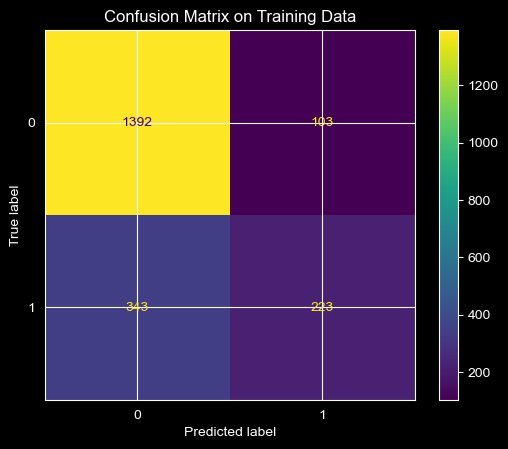

In [57]:
# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix using ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix on Training Data')

In [59]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from catboost import CatBoostClassifier

# Define column groups matching your notebook
num_cols = ['AGE', 'YOJ', 'INCOME', 'HOME_VAL', 'CAR_AGE']
passthrough_num = ['KIDSDRIV', 'HOMEKIDS', 'TRAVTIME', 'BLUEBOOK', 'TIF', 'OLDCLAIM', 'CLM_FREQ', 'MVR_PTS']
edu_col = ['EDUCATION']
binary_cols = ['PARENT1', 'MSTATUS', 'GENDER', 'CAR_USE', 'REVOKED', 'URBANICITY']
ohe_cols = ['OCCUPATION', 'CAR_TYPE']

# Build unified preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num_impute', KNNImputer(n_neighbors=2), num_cols),
        ('num_pass', 'passthrough', passthrough_num),
        ('edu', OrdinalEncoder(categories=[['<High School', 'High School', 'Bachelors', 'Masters', 'PhD']]), edu_col),
        ('bin', OrdinalEncoder(), binary_cols),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), ohe_cols)
    ],
    remainder='drop'
)

# Combine preprocessing + best model into one pipeline
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', CatBoostClassifier(random_state=42, verbose=0))
])

# Fit on un-encoded X_train (after currency & 'z_' string cleaning) and save
full_pipeline.fit(X_train_raw, y_train)
joblib.dump(full_pipeline, 'model_pipeline.joblib')

['model_pipeline.joblib']